# 0. IMPORT AND FUNCTION DECLARATION


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
# Plot Cumulative Returns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import make_scorer, recall_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import os
from xgboost import XGBClassifier
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

import google.auth
from google.auth.transport.requests import AuthorizedSession
from io import BytesIO


In [3]:
STRATEGY_SHEET_ID = '1XKeBA6hcnPLcdPixX5bWBtbDTBWP-MtK7Av8ead0NN0'

def reload_strategy_excel():
    """Export STRATEGY_ANALYSIS from Google Drive as an in-memory Excel workbook."""
    credentials, _ = google.auth.default(
        scopes=['https://www.googleapis.com/auth/drive.readonly']
    )
    session = AuthorizedSession(credentials)
    response = session.get(
        f'https://www.googleapis.com/drive/v3/files/{STRATEGY_SHEET_ID}/export',
        params={'mimeType': 'application/vnd.openxmlformats-officedocument.spreadsheetml.sheet'},
        timeout=120
    )
    response.raise_for_status()
    print('STRATEGY_ANALYSIS rechargé avec succès')
    return BytesIO(response.content)

strategy_excel = reload_strategy_excel()
strategy_workbook = pd.ExcelFile(strategy_excel)
print('Onglets disponibles :', strategy_workbook.sheet_names)


STRATEGY_ANALYSIS rechargé avec succès
Onglets disponibles : ['JPMORGAN', 'Historique', 'VIXHISTORIQUEMODEL', 'VIX HISTORIQUE', 'EQUITY BACKTEST STRATEGY', 'vsSTOXX50E']


In [4]:
def align_df_dates(df, column_names):
    aligned = []

    for i, name in enumerate(column_names):
        date_col = df.columns[2 * i]
        value_col = df.columns[2 * i + 1]

        temp = df[[date_col, value_col]].copy()
        temp.columns = ['Date', name]

        # Conserver uniquement le jour, sans l'heure
        temp['Date'] = pd.to_datetime(temp['Date'], errors='coerce').dt.normalize()
        temp[name] = pd.to_numeric(temp[name], errors='coerce')

        temp = temp.dropna(subset=['Date', name])
        temp = temp.drop_duplicates(subset='Date', keep='last')
        temp = temp.set_index('Date')

        aligned.append(temp)

    result = pd.concat(aligned, axis=1, join='inner')
    return result.sort_index()

# 1. GET MARKET DATA


In [5]:
#data = pd.read_excel('./data/ASSURANCE VIE.xlsx', sheet_name='VIXHISTORIQUEMODEL')
usecols_l = [0, 1, 2, 3, 5, 6, 7, 8, 9, 10]


In [6]:
data = pd.read_excel(strategy_workbook, sheet_name='VIX HISTORIQUE', skiprows=3, usecols=usecols_l)

In [7]:
# Dimensions
print("Dimensions :", data.shape)

# Aperçu des données
display(data.head(10))

# Types des colonnes et valeurs non nulles
data.info()

# Statistiques descriptives
display(data.describe(include='all').T)

# Valeurs manquantes par colonne
display(data.isna().sum().sort_values(ascending=False))

# Noms des colonnes
print("Colonnes :", data.columns.tolist())

Dimensions : (2118, 10)


,Date,Close,Date.1,Close.1,Date.2,Close.2,Date.3,Close.3,Date.4,Close.4
0,2018-06-08 16:00:00.288,2779.03,2018-06-08 15:15:59.904,12.18,2018-06-08 15:15:59.904,14.60,2018-06-08 15:15:59.904,16.13,2018-06-08 15:15:59.904,17.23
1,2018-06-11 16:00:00.288,2782.00,2018-06-11 15:15:59.904,12.35,2018-06-11 15:15:59.904,14.55,2018-06-11 15:15:59.904,16.12,2018-06-11 15:15:59.904,17.17
2,2018-06-12 16:00:00.288,2786.85,2018-06-12 15:15:59.904,12.34,2018-06-12 15:15:59.904,14.59,2018-06-12 15:15:59.904,16.17,2018-06-12 15:15:59.904,17.23
3,2018-06-13 16:00:00.288,2775.63,2018-06-13 15:15:59.904,12.94,2018-06-13 15:15:59.904,14.92,2018-06-13 15:15:59.904,16.43,2018-06-13 15:15:59.904,17.44
4,2018-06-14 16:00:00.288,2782.49,2018-06-14 15:15:59.904,12.12,2018-06-14 15:15:59.904,14.40,2018-06-14 15:15:59.904,16.09,2018-06-14 15:15:59.904,17.31
5,2018-06-15 16:00:00.288,2779.66,2018-06-15 15:15:59.904,11.98,2018-06-15 15:15:59.904,14.42,2018-06-15 15:15:59.904,16.32,2018-06-15 15:15:59.904,17.54
6,2018-06-18 16:00:00.288,2773.75,2018-06-18 15:15:59.904,12.31,2018-06-18 15:15:59.904,14.48,2018-06-18 15:15:59.904,16.35,2018-06-18 15:15:59.904,17.61
7,2018-06-19 16:00:00.288,2762.59,2018-06-19 15:15:59.904,13.35,2018-06-19 15:15:59.904,15.17,2018-06-19 15:15:59.904,16.89,2018-06-19 15:15:59.904,18.09
8,2018-06-20 16:00:00.288,2767.32,2018-06-20 15:15:59.904,12.79,2018-06-20 15:15:59.904,14.79,2018-06-20 15:15:59.904,16.52,2018-06-20 15:15:59.904,17.77
9,2018-06-21 16:00:00.288,2749.76,2018-06-21 15:15:59.904,14.64,2018-06-21 15:15:59.904,15.87,2018-06-21 15:15:59.904,17.20,2018-06-21 15:15:59.904,18.18


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2118 entries, 0 to 2117
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     2101 non-null   datetime64[ns]
 1   Close    2101 non-null   float64       
 2   Date.1   2118 non-null   datetime64[ns]
 3   Close.1  2118 non-null   float64       
 4   Date.2   2101 non-null   datetime64[ns]
 5   Close.2  2101 non-null   float64       
 6   Date.3   2100 non-null   datetime64[ns]
 7   Close.3  2100 non-null   float64       
 8   Date.4   2100 non-null   datetime64[ns]
 9   Close.4  2100 non-null   float64       
dtypes: datetime64[ns](5), float64(5)
memory usage: 165.6 KB


,count,mean,min,25%,50%,75%,max,std
Date,2101,2022-08-18 14:36:54.090950656,2018-06-08 16:00:00.288000,2020-07-16 16:00:00.288000,2022-08-17 16:00:00.288000,2024-09-20 16:00:00.288000,2026-10-26 16:00:00.288000,NaN
Close,2101.0,4528.219614,2237.4,3297.59,4266.49,5580.94,7818.93,1427.810663
Date.1,2118,2022-08-23 03:17:54.578583040,2018-06-08 15:15:59.904000,2020-07-22 21:15:59.904000,2022-08-30 03:15:59.904000,2024-09-20 09:15:59.904000,2026-10-26 15:15:59.904000,NaN
Close.1,2118.0,19.737597,10.85,15.0825,17.845,22.41,82.69,7.247324
Date.2,2101,2022-08-18 13:52:56.220405248,2018-06-08 15:15:59.904000,2020-07-16 15:15:59.904000,2022-08-17 15:15:59.904000,2024-09-20 15:15:59.904000,2026-10-26 15:15:59.904000,NaN
Close.2,2101.0,21.74604,13.93,17.3,20.31,24.78,72.98,6.325871
Date.3,2100,2022-08-18 04:54:36.704365568,2018-06-08 15:15:59.904000,2020-07-16 09:15:59.904000,2022-08-17 03:15:59.904000,2024-09-19 21:15:59.904000,2026-10-26 15:15:59.904000,NaN
Close.3,2100.0,23.086324,15.41,18.6475,21.97,26.3325,61.11,5.538115
Date.4,2100,2022-08-18 04:54:36.704365568,2018-06-08 15:15:59.904000,2020-07-16 09:15:59.904000,2022-08-17 03:15:59.904000,2024-09-19 21:15:59.904000,2026-10-26 15:15:59.904000,NaN
Close.4,2100.0,23.754505,16.76,20.19,23.035,27.27,45.86,4.527966


Date.3     18
Close.3    18
Date.4     18
Close.4    18
Date       17
Close      17
Date.2     17
Close.2    17
Date.1      0
Close.1     0
dtype: int64

Colonnes : ['Date', 'Close', 'Date.1', 'Close.1', 'Date.2', 'Close.2', 'Date.3', 'Close.3', 'Date.4', 'Close.4']


In [8]:
# Define the list of non-date column names
column_names = ['SPX', 'VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']





In [9]:
data= align_df_dates(data, column_names)


In [10]:
data

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
Date,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23
2018-06-11,2782.00,12.35,14.55,16.12,17.17
2018-06-12,2786.85,12.34,14.59,16.17,17.23
2018-06-13,2775.63,12.94,14.92,16.43,17.44
2018-06-14,2782.49,12.12,14.40,16.09,17.31
...,...,...,...,...,...
2026-10-20,7712.57,17.31,18.99,20.74,22.05
2026-10-21,7757.17,16.68,18.72,20.62,22.03
2026-10-22,7663.43,19.03,20.12,21.66,22.62


In [10]:
# data_open= pd.read_excel(strategy_workbook, sheet_name='VIX HISTORIQUE OPEN', skiprows=3, usecols=usecols_l)

In [11]:
# open_column_names = ['SPX_OPEN', 'VIX1M_OPEN', 'VIX3M_OPEN', 'VIX6M_OPEN', 'VIX1Y_OPEN']

In [12]:
# data_open=align_df_dates(data_open, open_column_names)

In [13]:
# data_open

,SPX_OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN
Date,,,,,


In [14]:
data_merged=data.join(data_open, how='inner') 

In [15]:
data_merged

,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,SPX_OPEN,VIX1M_OPEN,VIX3M_OPEN,VIX6M_OPEN,VIX1Y_OPEN
Date,,,,,,,,,,


In [11]:
print("Nombre d'observations :", len(data))
print("Période :", data.index.min(), "→", data.index.max())

print("\nValeurs manquantes :")
display(data.isna().sum())

print("\nDoublons de dates :", data.index.duplicated().sum())

print("\nStatistiques descriptives :")
display(data.describe().T)

print("\nCorrélations :")
display(data.corr().round(3))

Nombre d'observations : 2097
Période : 2018-06-08 00:00:00 → 2026-10-26 00:00:00

Valeurs manquantes :


SPX      0
VIX1M    0
VIX3M    0
VIX6M    0
VIX1Y    0
dtype: int64


Doublons de dates : 0

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
SPX,2097.0,4525.363963,1427.588743,2237.40,3295.47,4262.45,5572.07,7818.93
VIX1M,2097.0,19.771388,7.266134,10.85,15.11,17.87,22.48,82.69
VIX3M,2097.0,21.749051,6.331458,13.93,17.30,20.31,24.84,72.98
VIX6M,2097.0,23.089223,5.541520,15.41,18.64,21.99,26.34,61.11
VIX1Y,2097.0,23.756962,4.530707,16.76,20.19,23.05,27.27,45.86



Corrélations :


,SPX,VIX1M,VIX3M,VIX6M,VIX1Y
SPX,1.000,-0.236,-0.215,-0.155,-0.076
VIX1M,-0.236,1.000,0.969,0.911,0.808
VIX3M,-0.215,0.969,1.000,0.980,0.911
VIX6M,-0.155,0.911,0.980,1.000,0.969
VIX1Y,-0.076,0.808,0.911,0.969,1.000


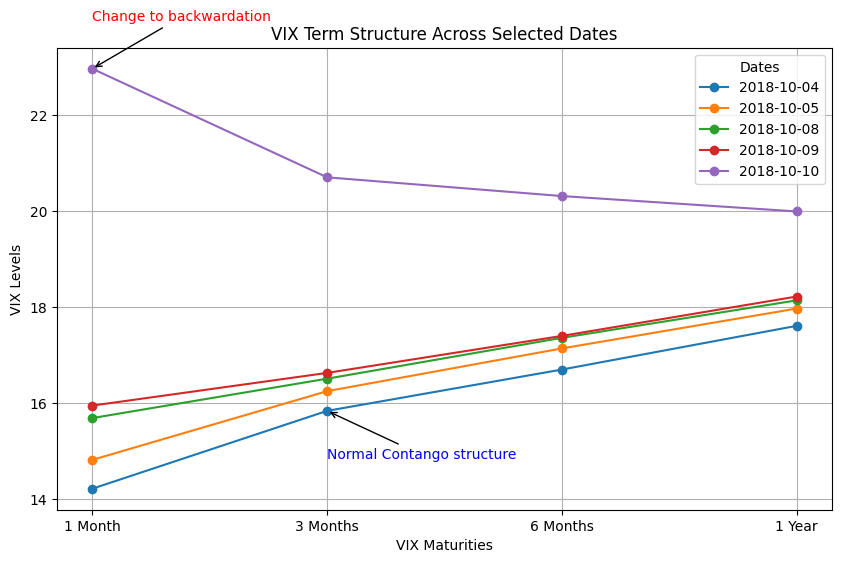

In [13]:
# Specify dates to plot the term structure for
selected_dates = ['2018-10-04', '2018-10-05', '2018-10-08', '2018-10-09', '2018-10-10']
vix_maturities = ['VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y']
maturity_labels = ['1 Month', '3 Months', '6 Months', '1 Year']

# Transpose the data for easier plotting
vix_data_transposed = data.loc[selected_dates, vix_maturities].transpose()

# Plot VIX term structure with maturities as X-axis
fig, ax = plt.subplots(figsize=(10, 6))

for date in selected_dates:
    ax.plot(maturity_labels, vix_data_transposed[date], marker='o', label=f"{date}")

# Highlight the VIX1M value for the last date
last_date = selected_dates[-1]
last_vix1m_value = vix_data_transposed.loc['VIX1M', last_date]
ax.annotate(
    "Change to backwardation",  # Annotation text
    xy=('1 Month', last_vix1m_value),  # Point being annotated
    xytext=('1 Month', last_vix1m_value + 1),  # Position of the text (numeric value)
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='red'
)

# Highlight the VIX3M value for the firt date: normal contango
first_date = selected_dates[0]
first_vix3m_value = vix_data_transposed.loc['VIX3M', first_date]
ax.annotate(
    "Normal Contango structure",  # Annotation text
    xy=('3 Months', first_vix3m_value),  # Point being annotated
    xytext=('3 Months', first_vix3m_value-1 ),  # Adjust upward for text placement
    arrowprops=dict(facecolor='red', arrowstyle='->'),  # Arrow properties
    fontsize=10,
    color='blue'
)


# Customize plot
ax.set_xlabel("VIX Maturities")
ax.set_ylabel("VIX Levels")
ax.set_title("VIX Term Structure Across Selected Dates")
ax.legend(title="Dates")
ax.grid()

# Save and show the plot
plt.savefig("./results/VIX_Term_Structure_Maturities.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. VIX MOVE IDENTIFICATION — RANDOM FOREST


In [16]:
CRASH_DAYS=5

In [17]:
# Calculate slopes (differences) between VIX maturities
vix_data = data.copy()

# Pentes de la structure à terme du VIX
vix_data['Slope_1M_3M'] = vix_data['VIX1M'] - vix_data['VIX3M']
vix_data['Slope_3M_6M'] = vix_data['VIX3M'] - vix_data['VIX6M']
vix_data['Slope_6M_1Y'] = vix_data['VIX6M'] - vix_data['VIX1Y']

display(vix_data.head())



,SPX,VIX1M,VIX3M,VIX6M,VIX1Y,Slope_1M_3M,Slope_3M_6M,Slope_6M_1Y
Date,,,,,,,,
2018-06-08,2779.03,12.18,14.60,16.13,17.23,-2.42,-1.53,-1.10
2018-06-11,2782.00,12.35,14.55,16.12,17.17,-2.20,-1.57,-1.05
2018-06-12,2786.85,12.34,14.59,16.17,17.23,-2.25,-1.58,-1.06
2018-06-13,2775.63,12.94,14.92,16.43,17.44,-1.98,-1.51,-1.01
2018-06-14,2782.49,12.12,14.40,16.09,17.31,-2.28,-1.69,-1.22


In [19]:
# Variation quotidienne du SPX
vix_data['SPX_Change'] = vix_data['SPX'].diff(1)

# Variations des VIX sur CRASH_DAYS séances
vix_data['VIX1M_Change'] = vix_data['VIX1M'].diff(CRASH_DAYS)
vix_data['VIX3M_Change'] = vix_data['VIX3M'].diff(CRASH_DAYS)
vix_data['VIX6M_Change'] = vix_data['VIX6M'].diff(CRASH_DAYS)
vix_data['VIX1Y_Change'] = vix_data['VIX1Y'].diff(CRASH_DAYS)


In [20]:
# Calculate the 75th percentile (upper quartile) for each relevant column
slope_1m_3m_threshold = vix_data['Slope_1M_3M'].abs().quantile(0.75)
slope_3m_6m_threshold = vix_data['Slope_3M_6M'].abs().quantile(0.75)
slope_6m_1y_threshold = vix_data['Slope_6M_1Y'].abs().quantile(0.75)

change_1m_threshold = vix_data['VIX1M_Change'].abs().quantile(0.75)
change_3m_threshold = vix_data['VIX3M_Change'].abs().quantile(0.75)
change_6m_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)
change_1y_threshold = vix_data['VIX6M_Change'].abs().quantile(0.75)

# Create the target variable `VIX_Significant_Change` using the calculated thresholds
vix_data['VIX_Significant_Change'] = (
    (vix_data['Slope_1M_3M'].abs() > slope_1m_3m_threshold) |
    (vix_data['Slope_3M_6M'].abs() > slope_3m_6m_threshold) |
    (vix_data['Slope_6M_1Y'].abs() > slope_6m_1y_threshold) |
    (vix_data['VIX1M_Change'].abs() > change_1m_threshold) |
    (vix_data['VIX3M_Change'].abs() > change_3m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_6m_threshold) |
    (vix_data['VIX6M_Change'].abs() > change_1y_threshold)
).astype(int)


In [21]:
vix_data['VIX_Significant_Change_next'] = vix_data['VIX_Significant_Change'].shift(-1)

In [22]:
vix_data.dropna(inplace=True)

In [23]:
vix_significant_change_sum = vix_data['VIX_Significant_Change'].sum()
print(vix_significant_change_sum)

1362


In [24]:
# Define feature set and target
X = vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']]
y = vix_data['VIX_Significant_Change_next']

In [25]:
split_point = int(len(X) * 0.8)

# Split the data<
X_train = X.iloc[:split_point]  # First 80% for training
X_test = X.iloc[split_point:]   # Last 20% for testing
y_train= y.iloc[:split_point]  # First 80% for training
y_test=y.iloc[split_point:]   # Last 20% for testing

In [26]:
# Initialize and train the model
stage1_model = RandomForestClassifier(random_state=42)
stage1_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = stage1_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.6778042959427207
Classification Report:
               precision    recall  f1-score   support

         0.0       0.58      0.45      0.51       155
         1.0       0.72      0.81      0.76       264

    accuracy                           0.68       419
   macro avg       0.65      0.63      0.63       419
weighted avg       0.67      0.68      0.67       419



ROC-AUC : 0.741


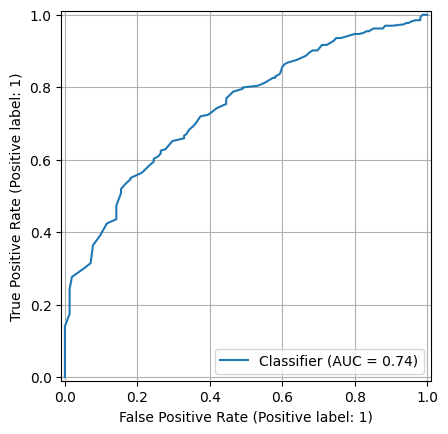

In [27]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

# Probabilités prédites pour la classe 1
y_proba = stage1_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_proba)

print(f"ROC-AUC : {auc:.3f}")

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.grid()
plt.show()

# 3. MODEL FEATURING


In [ ]:
# Use the Stage 1 model to make predictions on the entire dataset
vix_data['VIX_Shift_Prediction'] = stage1_model.predict(vix_data[['Slope_1M_3M', 'Slope_3M_6M', 'Slope_6M_1Y', 
                                                                  'VIX1M_Change', 'VIX3M_Change', 'VIX6M_Change', 'VIX1Y_Change']])


In [ ]:
# Create lagged features of `VIX_Shift_Prediction` and any other relevant features
vix_data['VIX_Shift_Prediction_Lag1'] = vix_data['VIX_Shift_Prediction'].shift(1)
vix_data['VIX_Shift_Prediction_Lag5'] = vix_data['VIX_Shift_Prediction'].shift(5)

vix_data['VIX_Shift_Prediction_Lag2'] = vix_data['VIX_Shift_Prediction'].shift(2)
vix_data['VIX_Shift_Prediction_Lag3'] = vix_data['VIX_Shift_Prediction'].shift(3)
vix_data['VIX_Shift_Prediction_Lag4'] = vix_data['VIX_Shift_Prediction'].shift(4)

In [ ]:
# Example crash flag based on a 5% drop over 5 days
CRASH_FLAG=-0.02


crash_label=f"Crash {CRASH_DAYS} Days"
vix_data['SPX_Change'] = vix_data['SPX'].pct_change(periods=CRASH_DAYS)
vix_data['crash_Flag'] = (vix_data['SPX_Change'] <= CRASH_FLAG).astype(int)


In [ ]:
vix_data[['SPX','SPX_Change']].head(10)

In [ ]:
crash_label

In [ ]:
# Shift the target variable 'crash_Flag' to represent the next day's crash
vix_data['Crash_Flag_Next_Day'] = vix_data['crash_Flag'].shift(-1)






In [ ]:
# Drop rows where the next day's crash flag is NaN (e.g., the last row)
vix_data.dropna(subset=['Crash_Flag_Next_Day'], inplace=True)

In [ ]:
vix_data.to_excel("./data/vix.xlsx", index=True)

In [ ]:
# Plot the SPX time series
plt.figure(figsize=(12, 6))
plt.plot(vix_data.index, vix_data['VIX3M'], label='VIX3M', color='blue', alpha=0.7)

# Highlight dates where crash_1M is 1
crash_dates = vix_data[vix_data['crash_Flag'] == 1]
plt.scatter(crash_dates.index, vix_data.loc[crash_dates.index, 'VIX3M'], color='red', label=crash_label, marker='x', s=100)

# Customize plot
plt.xlabel('Date')
plt.ylabel('SPX Value')
plt.title(f"SPX Time Series with Crash Flags set to {CRASH_FLAG:.2f}%")
plt.legend()
plt.grid(True)
plt.savefig("./results/SPX historical.png", dpi=300, bbox_inches="tight")

In [ ]:
crash_ratio= round(vix_data['crash_Flag'].sum()/len(vix_data)*100,2)
print(f"Pourcentage of crashes using the crash flag {CRASH_FLAG:.2f}%: {crash_ratio:.2f}%")

In [ ]:
#vix_data['SPX_pct_change'] = vix_data['SPX'].pct_change()

In [ ]:
vix_data.columns

In [ ]:
# List of items to remove
drop_columns = [ 'SPX__OPEN','SPX','crash_Flag','SPX_Change','Crash_Flag_Next_Day','VIX1M', 'VIX3M', 'VIX6M', 'VIX1Y','SPX_Same_Day_Change',
       'VIX1M_Same_Day_Change', 'VIX3M_Same_Day_Change',
       'VIX6M_Same_Day_Change', 'VIX1Y_Same_Day_Change',]
#drop_columns = [ 'crash_Flag','Crash_Flag_Next_Day']
# Filter the list
feature_columns = [item for item in vix_data.columns if item not in drop_columns]

# 4. MODEL TRAINING — XGBOOST


In [ ]:
vix_data

In [ ]:
feature_columns

In [ ]:
# Define features and target for Stage 2
X_stage2 = vix_data[feature_columns]
y_stage2 = vix_data['Crash_Flag_Next_Day']

# Drop rows with NaN values from lagged features
X_stage2 = X_stage2.dropna()
y_stage2 = y_stage2[X_stage2.index]



In [ ]:
# Define the split point for 80-20
split_point = int(len(X_stage2) * 0.8)

# Split the data
X_train_stage2 = X_stage2.iloc[:split_point]  # First 80% for training
X_test_stage2 = X_stage2.iloc[split_point:]   # Last 20% for testing
y_train_stage2= y_stage2.iloc[:split_point]  # First 80% for training
y_test_stage2=y_stage2.iloc[split_point:]   # Last 20% for testing

# Display split sizes
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
y_benchmark = data['SPX'].iloc[split_point:]

In [ ]:
# Train the model
# Calculate class imbalance ratio
imbalance_ratio = len(y_train_stage2[y_train_stage2 == 0]) / len(y_train_stage2[y_train_stage2 == 1])

# Adjust the model with scale_pos_weight
stage2_model = XGBClassifier(random_state=42, scale_pos_weight=imbalance_ratio)
stage2_model.fit(X_train_stage2, y_train_stage2)

# Evaluate the model
y_pred_stage2 = stage2_model.predict(X_test_stage2)
print("Accuracy:", accuracy_score(y_test_stage2, y_pred_stage2))
print("Classification Report:\n", classification_report(y_test_stage2, y_pred_stage2))


In [ ]:
# Calculate the confusion matrix
conf_matrix = confusion_matrix(y_test_stage2, y_pred_stage2)

# Normalize the confusion matrix
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Plot the normalized confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_normalized * 100, annot=True, fmt='.2f', cmap='Blues', xticklabels=['Non-crash', 'Crash'], yticklabels=['Non-crash', 'Crash'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix in Percentage')

# Save the figure
plt.savefig("./results/confusion_matrix_percentage.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box
#plt.show()



In [ ]:
# Get predicted probabilities for the "crash" class (usually the second column of predict_proba output)
proba_crash = stage2_model.predict_proba(X_test_stage2)[:, 1]

# Create a DataFrame for easier plotting
results = pd.DataFrame({
    'Date': X_test_stage2.index,            # Assuming 'Date' is the index
    'Crash_Probability': proba_crash,       # Predicted probability of crash
    'Actual_Crash': y_test_stage2           # Actual crash labels
})


# Filter the data to include only the dates where a crash actually occurred
crash_dates = results[results['Actual_Crash'] == 1]

# Plot the predicted crash probabilities on actual crash dates
plt.figure(figsize=(12, 6))
plt.scatter(crash_dates['Date'], crash_dates['Crash_Probability'], color='red')
plt.xlabel('Date')
plt.ylabel('Predicted Probability of Crash')
plt.title('Predicted Crash Probability on Actual Crash Dates')
plt.legend()
#plt.show()
plt.savefig("./results/Predictions.png", dpi=300, bbox_inches="tight")  # Save with high resolution and tight bounding box


In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(stage2_model, X_stage2, y_stage2, cv=tscv, scoring='accuracy')
print("TimeSeriesSplit Cross-Validation Accuracy Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

In [ ]:
# Assuming y_test_stage2 and y_pred_stage2 are available
precision = precision_score(y_test_stage2, y_pred_stage2, pos_label=1)
recall = recall_score(y_test_stage2, y_pred_stage2, pos_label=1)
f1 = f1_score(y_test_stage2, y_pred_stage2, pos_label=1)

print("Precision (Crash Class):", precision)
print("Recall (Crash Class):", recall)
print("F1-Score (Crash Class):", f1)

# 5. BACKTEST


In [ ]:
X_test_stage2.index

In [ ]:
results

In [ ]:
backtest_data=pd.DataFrame(data['SPX'])

In [ ]:
#backtest_data['Daily_Returns'] = backtest_data['SPX'].pct_change()
# Calculate percentage change between today and the next day
backtest_data['Daily_Returns'] = (backtest_data['SPX'].shift(-1) - backtest_data['SPX']) / backtest_data['SPX']

In [ ]:
backtest_data

In [ ]:
merged_data = pd.merge(results, backtest_data, left_index=True, right_index=True, how='inner')  # Inner join

In [ ]:
merged_data

In [ ]:
merged_data['Adjusted_Daily_Returns'] = merged_data.apply(
    lambda row: 0 if row['Crash_Probability'] >= 0.5 else row['Daily_Returns'], axis=1
)

In [ ]:
merged_data.dropna(inplace=True)

In [ ]:
# Initialize the starting index value
initial_index_value = 100

# Create the Index based on Daily_Returns
merged_data['Daily_Return_Index'] = initial_index_value * (1 + merged_data['Daily_Returns']).cumprod()

# Create the Index based on Adjusted_Daily_Returns
merged_data['Adjusted_Daily_Return_Index'] = initial_index_value * (1 + merged_data['Adjusted_Daily_Returns']).cumprod()



In [ ]:
# Display results
print("Final Benchmark Return:", merged_data['Daily_Return_Index'].iloc[-1])
print("Final Strategy Return:", merged_data['Adjusted_Daily_Return_Index'].iloc[-1])

In [ ]:
merged_data

In [ ]:
# Calculate the standard deviation of daily returns
std_daily_returns = merged_data['Daily_Returns'].std()
std_daily_returns_adjusted = merged_data['Adjusted_Daily_Returns'].std()
# Display results
print(f"Standard Deviation of Daily Returns: {std_daily_returns}")
print(f"Standard Deviation of Daily Returns adjusted: {std_daily_returns_adjusted}")

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(merged_data['Daily_Return_Index'], label='Benchmark')
plt.plot(merged_data['Adjusted_Daily_Return_Index'], label='Strategy')
plt.legend()
plt.title("Backtest of Strategy vs Benchmark")
plt.savefig("./results/AI_backtest.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
merged_data

In [ ]:
len(merged_data[merged_data['Actual_Crash'] ==1])/len(merged_data)

In [ ]:
len(merged_data[merged_data['Crash_Probability'] > 0.5])/len(merged_data)

In [ ]:
merged_data[merged_data['Crash_Probability'] > 0.5]